# Computer Vision Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Registration Number: 006**
 random seed = 6, HOG cell size = 8×8, SIFT grid = 6×6 (36 keypoints). Dataset: BloodMNIST, size 64. Classes: eosinophil (1), monocyte (5), neutrophil (6), platelet (7).


In [1]:
%pip -q install medmnist opencv-python-headless scikit-image scikit-learn seaborn

In [2]:
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import medmnist
from medmnist import INFO
from skimage.feature import hog
from skimage import exposure
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

SEED = 6
random.seed(SEED)
np.random.seed(SEED)

DATA_FLAG = 'bloodmnist'
info = INFO[DATA_FLAG]
DataClass = getattr(medmnist, info['python_class'])
CLASS_IDS = [1, 5, 6, 7]
CLASS_NAMES = {1: 'eosinophil', 5: 'monocyte', 6: 'neutrophil', 7: 'platelet'}
IMAGE_SIZE = 128
HOG_CELL = (8, 8)
SIFT_GRID = 6
SIFT_KEYPOINT_SIZE = 32
HOG_ORIENTATIONS = 9
HOG_CELLS_PER_BLOCK = (2, 2)
C_VALUES = [0.1, 1, 10]

print('Registration number: 006')
print('Random seed:', SEED)
print('HOG cell size:', HOG_CELL)
print('SIFT grid:', f'{SIFT_GRID} x {SIFT_GRID}', '=', SIFT_GRID*SIFT_GRID, 'keypoints')
print('Dataset:', info['python_class'], '| size 64')
print('Classes:', CLASS_NAMES)

Registration number: 006
Random seed: 6
HOG cell size: (8, 8)
SIFT grid: 6 x 6 = 36 keypoints
Dataset: BloodMNIST | size 64
Classes: {1: 'eosinophil', 5: 'monocyte', 6: 'neutrophil', 7: 'platelet'}


## Q1. Data setup



In [3]:
train_ds = DataClass(split='train', download=True, size=64)
val_ds = DataClass(split='val', download=True, size=64)
test_ds = DataClass(split='test', download=True, size=64)

def dataset_arrays(dataset):
    images = np.asarray(dataset.imgs)
    labels = np.asarray(dataset.labels).reshape(-1).astype(int)
    return images, labels

X_train_raw, y_train_raw = dataset_arrays(train_ds)
X_val_raw, y_val_raw = dataset_arrays(val_ds)
X_test_raw, y_test_raw = dataset_arrays(test_ds)

def choose_subset(images, labels, per_class, seed):
    rng = np.random.default_rng(seed)
    selected_indices = []
    for class_id in CLASS_IDS:
        indices = np.flatnonzero(labels == class_id)
        if len(indices) < per_class:
            raise ValueError(f'Class {class_id} has only {len(indices)} images; need {per_class}.')
        selected_indices.extend(rng.choice(indices, size=per_class, replace=False).tolist())
    rng.shuffle(selected_indices)
    return images[selected_indices], labels[selected_indices]

X_train_raw, y_train = choose_subset(X_train_raw, y_train_raw, 100, SEED)
X_val_raw, y_val = choose_subset(X_val_raw, y_val_raw, 30, SEED + 1)
X_test_raw, y_test = choose_subset(X_test_raw, y_test_raw, 30, SEED + 2)

def prepare_image(image):
    if image.ndim == 3:
        if image.shape[-1] == 1:
            gray = image[..., 0]
        else:
            gray = cv2.cvtColor(image.astype(np.uint8), cv2.COLOR_RGB2GRAY)
    else:
        gray = image
    gray = cv2.resize(gray.astype(np.uint8), (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_AREA)
    return gray

X_train = np.stack([prepare_image(im) for im in X_train_raw])
X_val = np.stack([prepare_image(im) for im in X_val_raw])
X_test = np.stack([prepare_image(im) for im in X_test_raw])

def print_split(name, images, labels):
    print(f'\n{name}: shape={images.shape}, labels shape={labels.shape}')
    print(pd.Series(labels).map(CLASS_NAMES).value_counts().reindex(
        [CLASS_NAMES[c] for c in CLASS_IDS], fill_value=0).to_string())

print_split('Train', X_train, y_train)
print_split('Validation', X_val, y_val)
print_split('Test', X_test, y_test)

100%|██████████| 156M/156M [01:20<00:00, 1.95MB/s]



Train: shape=(400, 128, 128), labels shape=(400,)
eosinophil    100
monocyte      100
neutrophil    100
platelet      100

Validation: shape=(120, 128, 128), labels shape=(120,)
eosinophil    30
monocyte      30
neutrophil    30
platelet      30

Test: shape=(120, 128, 128), labels shape=(120,)
eosinophil    30
monocyte      30
neutrophil    30
platelet      30


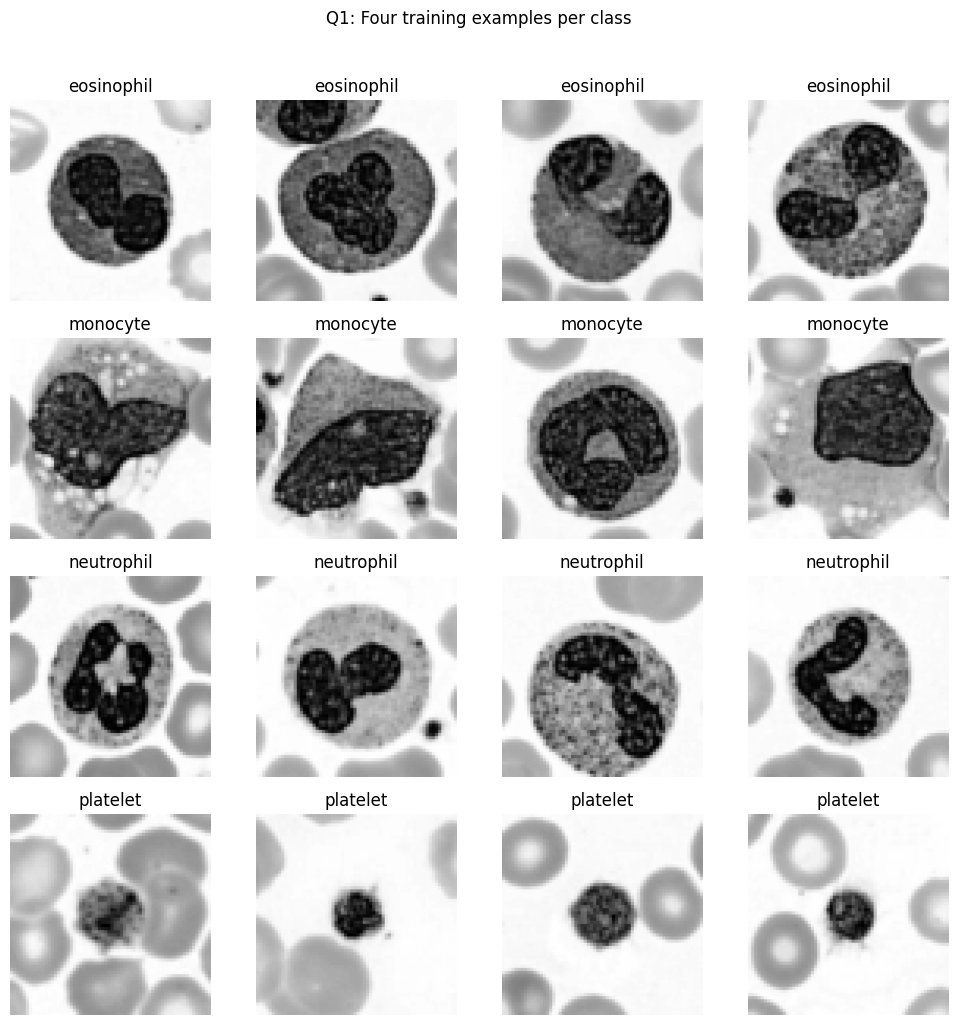

In [4]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for row, class_id in enumerate(CLASS_IDS):
    indices = np.flatnonzero(y_train == class_id)[:4]
    for col, idx in enumerate(indices):
        axes[row, col].imshow(X_train[idx], cmap='gray')
        axes[row, col].set_title(CLASS_NAMES[class_id])
        axes[row, col].axis('off')
plt.suptitle('Q1: Four training examples per class', y=1.02)
plt.tight_layout()
plt.show()

## Q2. HOG + SVM

HOG uses 9 orientations, 2×2 cells per block, and your personalized 8×8 pixel cell size. The validation set is used to choose C. The test set is not used in this question.

In [5]:
def extract_hog(image, visualize=False):
    result = hog(
        image,
        orientations=HOG_ORIENTATIONS,
        pixels_per_cell=HOG_CELL,
        cells_per_block=HOG_CELLS_PER_BLOCK,
        block_norm='L2-Hys',
        transform_sqrt=True,
        feature_vector=True,
        visualize=visualize
    )
    return result

hog_sample = extract_hog(X_train[0])
print('HOG feature length:', len(hog_sample))
print('Hand calculation:')
print('Image: 128 x 128 pixels; cell: 8 x 8 pixels')
print('Cells per image: (128/8) x (128/8) = 16 x 16')
print('Blocks: (16-2+1) x (16-2+1) = 15 x 15')
print('Values per block: 2 x 2 cells x 9 orientations = 36')
print('Total HOG features: 15 x 15 x 36 = 8100')
assert len(hog_sample) == 8100, f'Unexpected HOG feature length: {len(hog_sample)}'

HOG feature length: 8100
Hand calculation:
Image: 128 x 128 pixels; cell: 8 x 8 pixels
Cells per image: (128/8) x (128/8) = 16 x 16
Blocks: (16-2+1) x (16-2+1) = 15 x 15
Values per block: 2 x 2 cells x 9 orientations = 36
Total HOG features: 15 x 15 x 36 = 8100


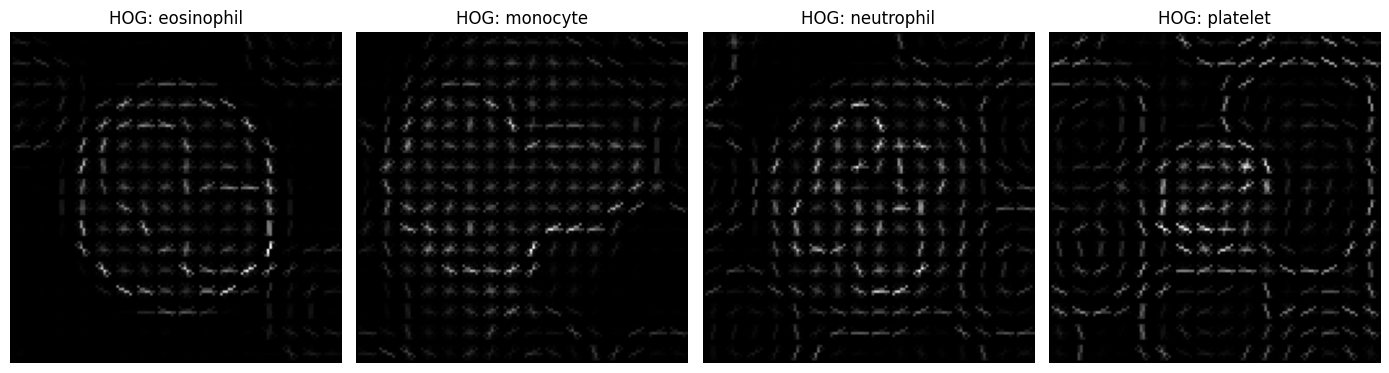

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, class_id in zip(axes, CLASS_IDS):
    idx = np.flatnonzero(y_train == class_id)[0]
    _, hog_image = extract_hog(X_train[idx], visualize=True)
    ax.imshow(exposure.rescale_intensity(hog_image, in_range='image', out_range=(0, 1)), cmap='gray')
    ax.set_title(f'HOG: {CLASS_NAMES[class_id]}')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [7]:
def hog_features(images):
    return np.stack([extract_hog(im) for im in images]).astype(np.float32)

X_train_hog = hog_features(X_train)
X_val_hog = hog_features(X_val)

hog_results = []
hog_models = {}
for c in C_VALUES:
    model = make_pipeline(StandardScaler(), LinearSVC(C=c, random_state=SEED, max_iter=10000))
    model.fit(X_train_hog, y_train)
    pred = model.predict(X_val_hog)
    score = f1_score(y_val, pred, average='macro', zero_division=0)
    hog_results.append({'C': c, 'Validation accuracy': accuracy_score(y_val, pred), 'Validation macro-F1': score})
    hog_models[c] = model

hog_results_df = pd.DataFrame(hog_results)
display(hog_results_df)
best_hog_c = float(hog_results_df.sort_values(['Validation macro-F1', 'Validation accuracy'], ascending=False).iloc[0]['C'])
hog_model = hog_models[best_hog_c]
hog_val_pred = hog_model.predict(X_val_hog)
print('Selected HOG C:', best_hog_c)
print('Validation accuracy:', round(accuracy_score(y_val, hog_val_pred), 4))
print('Validation macro-F1:', round(f1_score(y_val, hog_val_pred, average='macro', zero_division=0), 4))
print('Validation confusion matrix (rows=true, columns=predicted; class order 1,5,6,7):')
print(confusion_matrix(y_val, hog_val_pred, labels=CLASS_IDS))

,C,Validation accuracy,Validation macro-F1
0,0.1,0.733333,0.730822
1,1.0,0.733333,0.730822
2,10.0,0.733333,0.730822


Selected HOG C: 0.1
Validation accuracy: 0.7333
Validation macro-F1: 0.7308
Validation confusion matrix (rows=true, columns=predicted; class order 1,5,6,7):
[[16  4  9  1]
 [ 4 22  4  0]
 [ 6  4 20  0]
 [ 0  0  0 30]]


## Q3. SIFT + SVM

First inspect normal SIFT detection, which can produce a different number of descriptors per image. Then use a fixed 6×6 grid with keypoint size 32 so each image has 36×128 = 4608 features.

Normal SIFT keypoints per training image:
Average: 75.51
Minimum: 8
Maximum: 232
Images with zero keypoints: 0 out of 400


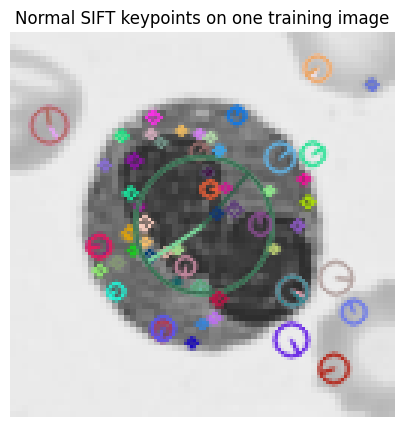

In [8]:
sift = cv2.SIFT_create()

normal_counts = []
normal_keypoints_for_example = None
normal_example_image = None
for class_id in CLASS_IDS:
    idx = np.flatnonzero(y_train == class_id)[0]
    image = X_train[idx]
    keypoints, descriptors = sift.detectAndCompute(image, None)
    normal_counts.append((class_id, len(keypoints)))
    if normal_keypoints_for_example is None:
        normal_keypoints_for_example = keypoints
        normal_example_image = image

counts_only = np.array([count for _, count in normal_counts], dtype=int)
all_counts = []
for image in X_train:
    keypoints, _ = sift.detectAndCompute(image, None)
    all_counts.append(len(keypoints))
all_counts = np.asarray(all_counts)
print('Normal SIFT keypoints per training image:')
print('Average:', round(float(all_counts.mean()), 2))
print('Minimum:', int(all_counts.min()))
print('Maximum:', int(all_counts.max()))
print('Images with zero keypoints:', int(np.sum(all_counts == 0)), 'out of', len(all_counts))

kp_img = cv2.drawKeypoints(normal_example_image, normal_keypoints_for_example, None,
                           flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5))
plt.imshow(kp_img, cmap='gray')
plt.title('Normal SIFT keypoints on one training image')
plt.axis('off')
plt.show()

In [9]:
def fixed_grid_sift(image):
    # Keep keypoint centers at least 16 pixels from the border for size-32 descriptors.
    positions = np.linspace(SIFT_KEYPOINT_SIZE / 2, IMAGE_SIZE - SIFT_KEYPOINT_SIZE / 2, SIFT_GRID)
    keypoints = []
    for y in positions:
        for x in positions:
            keypoints.append(cv2.KeyPoint(float(x), float(y), float(SIFT_KEYPOINT_SIZE)))
    _, descriptors = sift.compute(image, keypoints)
    if descriptors is None:
        descriptors = np.zeros((0, 128), dtype=np.float32)
    if len(descriptors) != SIFT_GRID * SIFT_GRID:
        # Keep a fixed-length vector even if OpenCV omits a border keypoint.
        padded = np.zeros((SIFT_GRID * SIFT_GRID, 128), dtype=np.float32)
        n = min(len(descriptors), len(padded))
        padded[:n] = descriptors[:n]
        descriptors = padded
    return descriptors.reshape(-1).astype(np.float32)

sift_sample = fixed_grid_sift(X_train[0])
print('SIFT grid:', f'{SIFT_GRID} x {SIFT_GRID}')
print('Grid keypoints:', SIFT_GRID * SIFT_GRID)
print('Descriptor length per keypoint: 128')
print('Hand calculation: 6 x 6 x 128 = 36 x 128 = 4608 features')
print('Actual feature length:', len(sift_sample))
assert len(sift_sample) == 4608

SIFT grid: 6 x 6
Grid keypoints: 36
Descriptor length per keypoint: 128
Hand calculation: 6 x 6 x 128 = 36 x 128 = 4608 features
Actual feature length: 4608


In [10]:
def sift_features(images):
    return np.stack([fixed_grid_sift(im) for im in images]).astype(np.float32)

X_train_sift = sift_features(X_train)
X_val_sift = sift_features(X_val)
print('SIFT training feature matrix:', X_train_sift.shape)
print('SIFT validation feature matrix:', X_val_sift.shape)

sift_results = []
sift_models = {}
for c in C_VALUES:
    model = make_pipeline(StandardScaler(), LinearSVC(C=c, random_state=SEED, max_iter=10000))
    model.fit(X_train_sift, y_train)
    pred = model.predict(X_val_sift)
    score = f1_score(y_val, pred, average='macro', zero_division=0)
    sift_results.append({'C': c, 'Validation accuracy': accuracy_score(y_val, pred), 'Validation macro-F1': score})
    sift_models[c] = model

sift_results_df = pd.DataFrame(sift_results)
display(sift_results_df)
best_sift_c = float(sift_results_df.sort_values(['Validation macro-F1', 'Validation accuracy'], ascending=False).iloc[0]['C'])
sift_model = sift_models[best_sift_c]
sift_val_pred = sift_model.predict(X_val_sift)
print('Selected SIFT C:', best_sift_c)
print('Validation accuracy:', round(accuracy_score(y_val, sift_val_pred), 4))
print('Validation macro-F1:', round(f1_score(y_val, sift_val_pred, average='macro', zero_division=0), 4))
print('Validation confusion matrix (rows=true, columns=predicted; class order 1,5,6,7):')
print(confusion_matrix(y_val, sift_val_pred, labels=CLASS_IDS))

SIFT training feature matrix: (400, 4608)
SIFT validation feature matrix: (120, 4608)


,C,Validation accuracy,Validation macro-F1
0,0.1,0.758333,0.753670
1,1.0,0.758333,0.753393
2,10.0,0.758333,0.753393


Selected SIFT C: 0.1
Validation accuracy: 0.7583
Validation macro-F1: 0.7537
Validation confusion matrix (rows=true, columns=predicted; class order 1,5,6,7):
[[14  3 12  1]
 [ 6 23  1  0]
 [ 5  0 24  1]
 [ 0  0  0 30]]


## Q4. Robustness

In [11]:
def rotate_image(image, angle=20):
    center = (image.shape[1] / 2, image.shape[0] / 2)
    matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
    rotated = cv2.warpAffine(image, matrix, (image.shape[1], image.shape[0]),
                             flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    return rotated

def noisy_image(image, sigma=0.05, rng=None):
    if rng is None:
        rng = np.random.default_rng(SEED)
    scaled = image.astype(np.float32) / 255.0
    noisy = scaled + rng.normal(0.0, sigma, scaled.shape).astype(np.float32)
    noisy = np.clip(noisy, 0.0, 1.0)
    return np.round(noisy * 255.0).astype(np.uint8)

rng_noise = np.random.default_rng(SEED + 3)
X_test_clean = X_test.copy()
X_test_rotated = np.stack([rotate_image(im, 20) for im in X_test])
X_test_noisy = np.stack([noisy_image(im, 0.05, rng_noise) for im in X_test])

# Feature extraction for the three test conditions; no retraining is performed.
X_test_hog_clean = hog_features(X_test_clean)
X_test_hog_rotated = hog_features(X_test_rotated)
X_test_hog_noisy = hog_features(X_test_noisy)

X_test_sift_clean = sift_features(X_test_clean)
X_test_sift_rotated = sift_features(X_test_rotated)
X_test_sift_noisy = sift_features(X_test_noisy)

robustness_rows = []
for model_name, model, features in [
    ('HOG + SVM', hog_model, [X_test_hog_clean, X_test_hog_rotated, X_test_hog_noisy]),
    ('SIFT + SVM', sift_model, [X_test_sift_clean, X_test_sift_rotated, X_test_sift_noisy])
]:
    accuracies = [accuracy_score(y_test, model.predict(x)) for x in features]
    robustness_rows.append({
        'Model': model_name,
        'Clean accuracy': accuracies[0],
        'Rotated accuracy': accuracies[1],
        'Noisy accuracy': accuracies[2]
    })

robustness_df = pd.DataFrame(robustness_rows)
display(robustness_df.round(4))

,Model,Clean accuracy,Rotated accuracy,Noisy accuracy
0,HOG + SVM,0.7417,0.6917,0.250
1,SIFT + SVM,0.7083,0.7250,0.725


In [12]:
print('Q4 interpretation based on the measured test accuracies:')
for _, row in robustness_df.iterrows():
    print(f"{row['Model']}: clean={row['Clean accuracy']:.4f}, rotated={row['Rotated accuracy']:.4f}, noisy={row['Noisy accuracy']:.4f}.")

hog_rotation_drop = robustness_df.loc[robustness_df['Model'] == 'HOG + SVM', 'Clean accuracy'].iloc[0] - robustness_df.loc[robustness_df['Model'] == 'HOG + SVM', 'Rotated accuracy'].iloc[0]
sift_rotation_drop = robustness_df.loc[robustness_df['Model'] == 'SIFT + SVM', 'Clean accuracy'].iloc[0] - robustness_df.loc[robustness_df['Model'] == 'SIFT + SVM', 'Rotated accuracy'].iloc[0]
hog_noise_drop = robustness_df.loc[robustness_df['Model'] == 'HOG + SVM', 'Clean accuracy'].iloc[0] - robustness_df.loc[robustness_df['Model'] == 'HOG + SVM', 'Noisy accuracy'].iloc[0]
sift_noise_drop = robustness_df.loc[robustness_df['Model'] == 'SIFT + SVM', 'Clean accuracy'].iloc[0] - robustness_df.loc[robustness_df['Model'] == 'SIFT + SVM', 'Noisy accuracy'].iloc[0]

print()
print('Rotation prediction correct:', 'Yes' if (hog_rotation_drop > sift_rotation_drop) else 'No / not supported by this run')
print('Noise prediction: HOG lost more accuracy' if hog_noise_drop > sift_noise_drop else
      'Noise prediction: SIFT lost more accuracy' if sift_noise_drop > hog_noise_drop else
      'Noise prediction: both lost the same amount of accuracy')
print('Write three sentences in your own words using the displayed table and these measured drops.')

Q4 interpretation based on the measured test accuracies:
HOG + SVM: clean=0.7417, rotated=0.6917, noisy=0.2500.
SIFT + SVM: clean=0.7083, rotated=0.7250, noisy=0.7250.

Rotation prediction correct: Yes
Noise prediction: HOG lost more accuracy
Write three sentences in your own words using the displayed table and these measured drops.


## Q5. Short answers and AI log



In [13]:
def most_confused_pair(cm, class_ids):
    cm = np.asarray(cm).copy()
    np.fill_diagonal(cm, 0)
    if cm.max() == 0:
        return 'No off-diagonal confusions in this matrix.'
    i, j = np.unravel_index(np.argmax(cm), cm.shape)
    return f'{CLASS_NAMES[class_ids[i]]} predicted as {CLASS_NAMES[class_ids[j]]}: {cm[i, j]} cases'

hog_cm = confusion_matrix(y_val, hog_val_pred, labels=CLASS_IDS)
sift_cm = confusion_matrix(y_val, sift_val_pred, labels=CLASS_IDS)
print('Largest HOG validation confusion:', most_confused_pair(hog_cm, CLASS_IDS))
print('Largest SIFT validation confusion:', most_confused_pair(sift_cm, CLASS_IDS))

Largest HOG validation confusion: eosinophil predicted as neutrophil: 9 cases
Largest SIFT validation confusion: eosinophil predicted as neutrophil: 12 cases


### Q5(a). Why does HOG use block normalisation?

HOG block normalisation reduces the effect of overall brightness and contrast changes by scaling gradient histograms within a local block. This makes the feature representation more stable under illumination changes.

### Q5(b). Why is it wrong to choose C using the test set?

Choosing C on the test set leaks information from the final evaluation data into model selection. This makes the reported test performance optimistically biased and no longer an independent estimate of generalisation; C should be selected using validation data only.

### Q5(c). Which two classes were confused most, and why might grayscale make this harder?

Use the class-pair outputs above and the validation confusion matrices to state which pair was confused most by your model. Grayscale removes color information that could help distinguish blood-cell types, so classes with similar shapes and textures may be harder to separate.

